# IE6600 Hackathon — Energy & Climate: *Clean energy got cheap. Did we switch?*
**Group #:** _fill in_ · **Team:** Nehal, Taniya, Tyler

| Section | Question | Owner | Data |
|---|---|---|---|
| Q1 | How much have solar and wind costs fallen compared with coal and gas? | Nehal | Lazard LCOE+ v18.0; IRENA (2026) |
| Q2 | How fast has the electricity mix changed in the US and worldwide? | Tyler | Our World in Data |
| Q3 | Which countries are switching fastest? | Taniya | Our World in Data (Ember; Energy Institute) |

## 0. Setup: shared libraries, team palette and file finder

In [24]:
%pip install openpyxl

Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 26.2.1 -> 26.2.2
[notice] To update, run: C:\Users\Tyler\AppData\Local\Python\pythoncore-3.14-64\python.exe -m pip install --upgrade pip


In [25]:
import os, glob, textwrap
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# Team palette (one palette across every chart and slide)
AMBER, BLUE, PURPLE, GRAY, NAVY = "#E0A800", "#2C6FAC", "#8E6CB4", "#5A6573", "#1E2A38"
plt.rcParams["font.family"] = ["Arial", "DejaVu Sans"]

def find_file(pattern):
    """Look for a data file next to the notebook, then in Downloads / Desktop."""
    for p in ["", "~/Downloads/", "~/OneDrive/Downloads/", "~/Desktop/", "~/OneDrive/Desktop/"]:
        hits = glob.glob(os.path.expanduser(p + pattern))
        if hits:
            print("Using file:", hits[0])
            return hits[0]
    raise FileNotFoundError(f"Couldn't find {pattern}. Put it in the same folder as this notebook.")

# One shared data source for all three questions: the team workbook.
# Accepts "IE6600 - Hackathon Team 4.xlsx", "IE6600 - Hackathon.xlsx", "... (1).xlsx", etc.
DATA_FILE = None
for pattern in ["*Hackathon*Team*4*.xlsx", "*Hackathon*.xlsx", "*hackathon*.xlsx"]:
    try:
        DATA_FILE = find_file(pattern)
        break
    except FileNotFoundError:
        pass
if DATA_FILE is None:
    raise FileNotFoundError("Couldn't find the team workbook. Download it from Google Sheets as .xlsx "
                            "(File > Download > Microsoft Excel) and put it in the same folder as this notebook.")

Using file: IE6600 - Hackathon.xlsx


---
# Q1 (Nehal): How much have solar and wind costs fallen compared with coal and gas?
## Q1a. US cost of new power plants, 2009–2025 (Lazard)
**Source:** Lazard LCOE+ June 2025 (v18.0), p.14, Historical LCOE Comparison — https://www.lazard.com/media/5tlbhyla/lazards-lcoeplus-june-2025-_vf.pdf#page=14
Values are the mean of each low/high unsubsidized range, nominal US $/MWh. 2022 was not published.

In [26]:
q1_raw = pd.read_excel(DATA_FILE, sheet_name="Q1 Raw data", header=3)
q1_raw = q1_raw.loc[:, ~q1_raw.columns.astype(str).str.strip().isin(["", "nan"]) & ~q1_raw.columns.astype(str).str.startswith((" ", "Unnamed"))]

LAZ_TECHS = ["Utility-scale solar", "Onshore wind", "Coal", "Gas combined cycle"]
laz = q1_raw[q1_raw["Source"].str.startswith("Lazard")]
laz_long = (laz.rename(columns={"Solar PV": "Utility-scale solar"})
               .melt(id_vars="Year", value_vars=LAZ_TECHS, var_name="Technology", value_name="LCOE_usd_mwh")
               .dropna(subset=["LCOE_usd_mwh"]))
laz_long.head()

,Year,Technology,LCOE_usd_mwh
0,2009,Utility-scale solar,359.0
1,2010,Utility-scale solar,248.0
2,2011,Utility-scale solar,157.0
3,2012,Utility-scale solar,125.0
4,2013,Utility-scale solar,98.0


In [27]:
# Pivot: years down, technologies across. reindex() puts the unpublished 2022 back as a blank row
laz_pivot = laz_long.pivot_table(index="Year", columns="Technology", values="LCOE_usd_mwh", aggfunc="mean")
laz_pivot = laz_pivot.reindex(range(laz_pivot.index.min(), laz_pivot.index.max() + 1))[LAZ_TECHS]
laz_pivot.round(0)

Technology,Utility-scale solar,Onshore wind,Coal,Gas combined cycle
Year,,,,
2009,359.0,135.0,111.0,83.0
2010,248.0,124.0,111.0,82.0
2011,157.0,71.0,111.0,83.0
2012,125.0,72.0,102.0,75.0
2013,98.0,70.0,105.0,74.0
2014,79.0,59.0,109.0,74.0
2015,64.0,55.0,108.0,65.0
2016,55.0,47.0,102.0,63.0
2017,50.0,45.0,102.0,60.0


In [28]:
# Summary: the fall (2009-2021) vs the rebound (2021-2025), nominal dollars
laz_summary = pd.DataFrame({y: laz_pivot.loc[y] for y in (2009, 2021, 2025)})
laz_summary.columns = ["2009", "2021", "2025"]
for a, b in [("2009", "2021"), ("2021", "2025"), ("2009", "2025")]:
    laz_summary[f"Change {a}-{b}"] = (laz_summary[b] / laz_summary[a] - 1).mul(100).round(1).astype(str) + "%"
laz_summary

,2009,2021,2025,Change 2009-2021,Change 2021-2025,Change 2009-2025
Technology,,,,,,
Utility-scale solar,359.0,36.0,58.0,-90.0%,61.1%,-83.8%
Onshore wind,135.0,38.0,61.0,-71.9%,60.5%,-54.8%
Coal,111.0,108.0,122.0,-2.7%,13.0%,9.9%
Gas combined cycle,83.0,60.0,78.0,-27.7%,30.0%,-6.0%


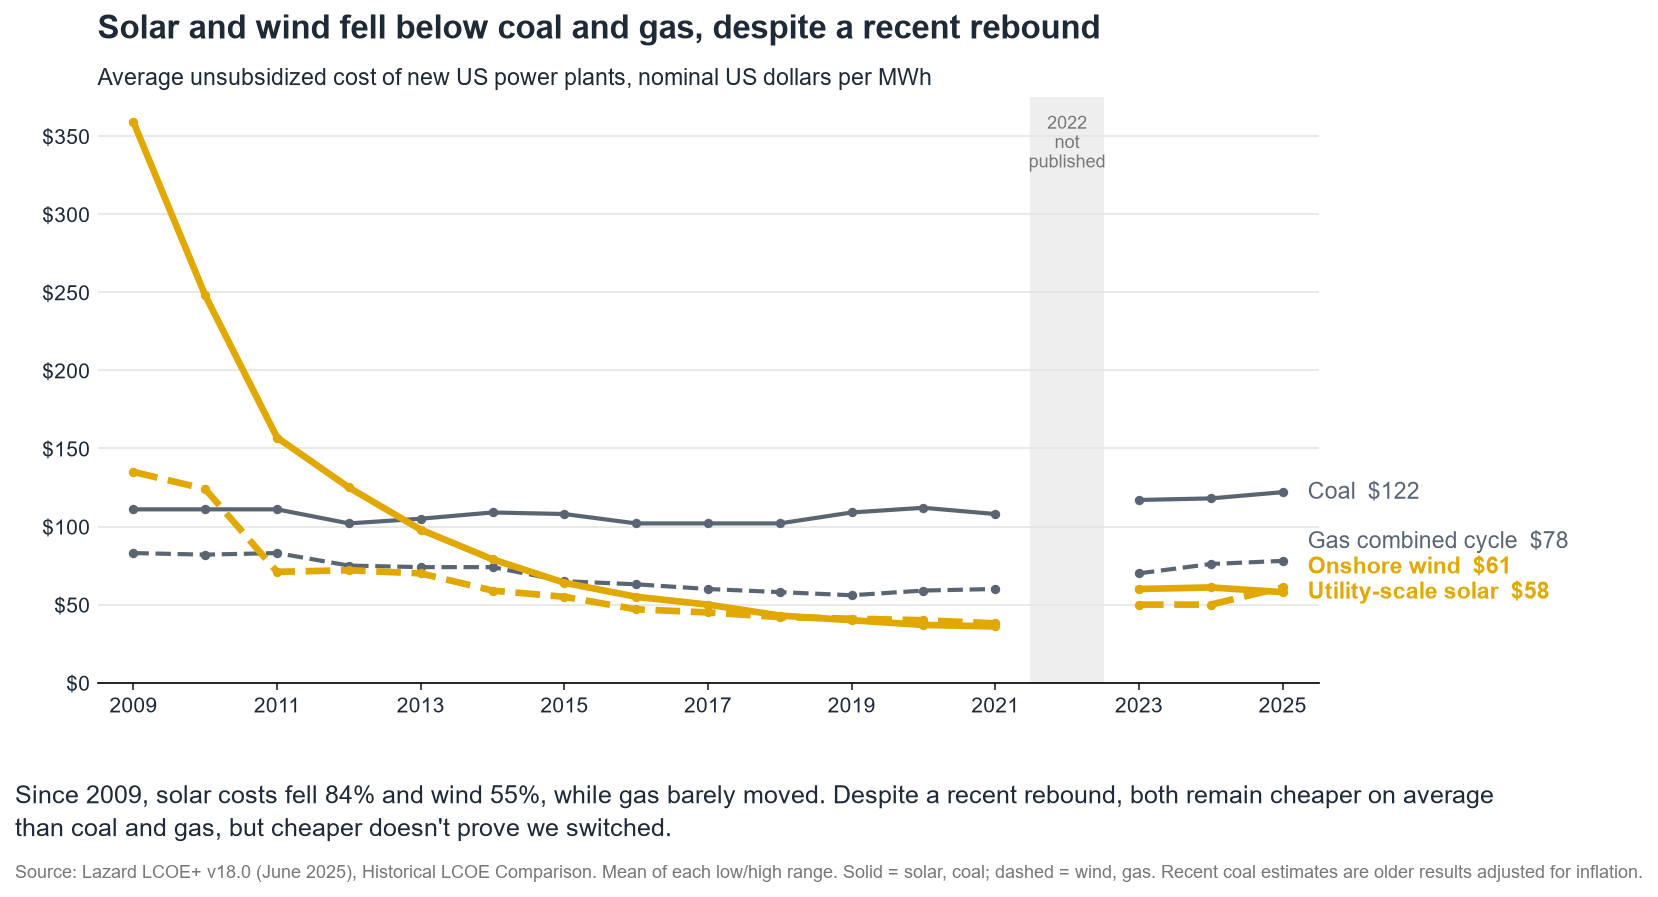

In [29]:
TITLE = "Solar and wind fell below coal and gas, despite a recent rebound"
STYLE = {"Utility-scale solar": (AMBER, "-", 3.2), "Onshore wind": (AMBER, "--", 3.2),
         "Coal": (GRAY, "-", 2.0), "Gas combined cycle": (GRAY, "--", 2.0)}

fig, ax = plt.subplots(figsize=(11, 6.2), dpi=150)
for tech, (color, ls, lw) in STYLE.items():
    s = laz_pivot[tech]
    ax.plot(s.index, s.values, color=color, linestyle=ls, linewidth=lw, marker="o", markersize=3.5,
            zorder=3 if color == AMBER else 2)

# End-of-line labels, nudged apart so close values don't overlap
last = laz_pivot.index.max()
ends = laz_pivot.loc[last].sort_values()
gap, prev, label_y = 0.045 * laz_pivot.max().max(), -np.inf, {}
for tech, val in ends.items():
    label_y[tech] = max(val, prev + gap); prev = label_y[tech]
for tech, val in ends.items():
    c = STYLE[tech][0]
    ax.annotate(f"{tech}  ${val:.0f}", xy=(last, val), xytext=(last + 0.35, label_y[tech]), va="center",
                fontsize=11, color=c, fontweight="bold" if c == AMBER else "normal")

ax.axvspan(2021.5, 2022.5, color="#EEEEEE", zorder=0)
ax.text(2022, ax.get_ylim()[1] * 0.97, "2022\nnot\npublished", ha="center", va="top", fontsize=8.5, color="#777777")
ax.set_title(TITLE, loc="left", fontsize=16, fontweight="bold", color=NAVY, pad=28)
ax.text(0, 1.02, "Average unsubsidized cost of new US power plants, nominal US dollars per MWh",
        transform=ax.transAxes, fontsize=11, color=NAVY)
ax.set_xticks(range(2009, 2026, 2)); ax.set_xlim(2008.5, 2025.5); ax.set_ylim(bottom=0)
ax.yaxis.set_major_formatter(lambda v, _: f"${v:.0f}")
ax.grid(axis="y", color="#E5E5E5", linewidth=0.8)
for side in ("top", "right", "left"):
    ax.spines[side].set_visible(False)
ax.tick_params(axis="y", length=0, colors=NAVY); ax.tick_params(axis="x", colors=NAVY)

OBSERVATION = ("Since 2009, solar costs fell 84% and wind 55%, while gas barely moved. Despite a recent rebound, "
               "both remain cheaper on average than coal and gas, but cheaper doesn't prove we switched.")
fig.text(0.01, 0.115, textwrap.fill(OBSERVATION, width=130), fontsize=12, color=NAVY, va="top", linespacing=1.4)
fig.text(0.01, 0.01, "Source: Lazard LCOE+ v18.0 (June 2025), Historical LCOE Comparison. Mean of each low/high range. "
         "Solid = solar, coal; dashed = wind, gas. Recent coal estimates are older results adjusted for inflation.",
         fontsize=8.5, color="#777777")
fig.subplots_adjust(left=0.06, right=0.80, top=0.85, bottom=0.22)
fig.savefig("q1_chart1_lazard_cost_over_time.png", dpi=300, bbox_inches="tight")
plt.show()

**Interpretation (Q1a):** Between 2009 and 2025, the estimated average cost of new US power projects fell by about 84% for utility-scale solar and 55% for onshore wind, compared with a 6% decrease for gas and a 10% increase for coal (nominal dollars). On average both remained cheaper than coal and gas in 2025 ($58 and $61 per MWh, versus $78 for gas and $122 for coal), but cost data alone cannot show whether the US actually switched. 2022 was not published by Lazard.

## Q1b. Global and US cost of new solar and wind, 2010–2025 (IRENA)
**Source:** IRENA (2026), *Renewable Power Generation Costs in 2025*, data file — https://www.irena.org/Publications/2026/Jul/Renewable-Power-Generation-Costs-in-2025
Data: the IRENA rows of the `Q1 Raw data` tab (originally Fig 3.7: solar PV, 15 markets; Fig 2.11: onshore wind, 30 markets; Fig S.2: world weighted averages). Real 2025 US $/MWh.
The deck uses the **2025 US vs World bar chart built in Excel**; this section shows the cleaning and the full country picture behind it.

In [30]:
# IRENA rows from the Q1 Raw data tab: countries + world average, real 2025 $/MWh
irena = q1_raw[q1_raw["Source"].astype(str).str.startswith("IRENA")].copy()
irena["Country"] = irena["Region"].replace({"World": "Global average"})
irena = (irena.melt(id_vars=["Country", "Year"], value_vars=["Solar PV", "Onshore wind"],
                    var_name="Technology", value_name="LCOE")
              .dropna(subset=["LCOE"]))
irena["Year"] = irena["Year"].astype(int)
print(irena.groupby("Technology")["Country"].nunique(), len(irena), "rows")

Technology
Onshore wind    31
Solar PV        16
Name: Country, dtype: int64 578 rows


In [31]:
irena_solar = irena[irena.Technology == "Solar PV"].pivot_table(index="Year", columns="Country", values="LCOE")
irena_wind = irena[irena.Technology == "Onshore wind"].pivot_table(index="Year", columns="Country", values="LCOE")

# The numbers behind the Excel bar chart: 2025, US vs World
bar_2025 = pd.DataFrame({"Solar PV": [irena_solar.loc[2025, "United States"], irena_solar.loc[2025, "Global average"]],
                         "Onshore wind": [irena_wind.loc[2025, "United States"], irena_wind.loc[2025, "Global average"]]},
                        index=["United States", "World"]).round(1)
bar_2025

,Solar PV,Onshore wind
United States,62.0,39.8
World,43.5,33.0


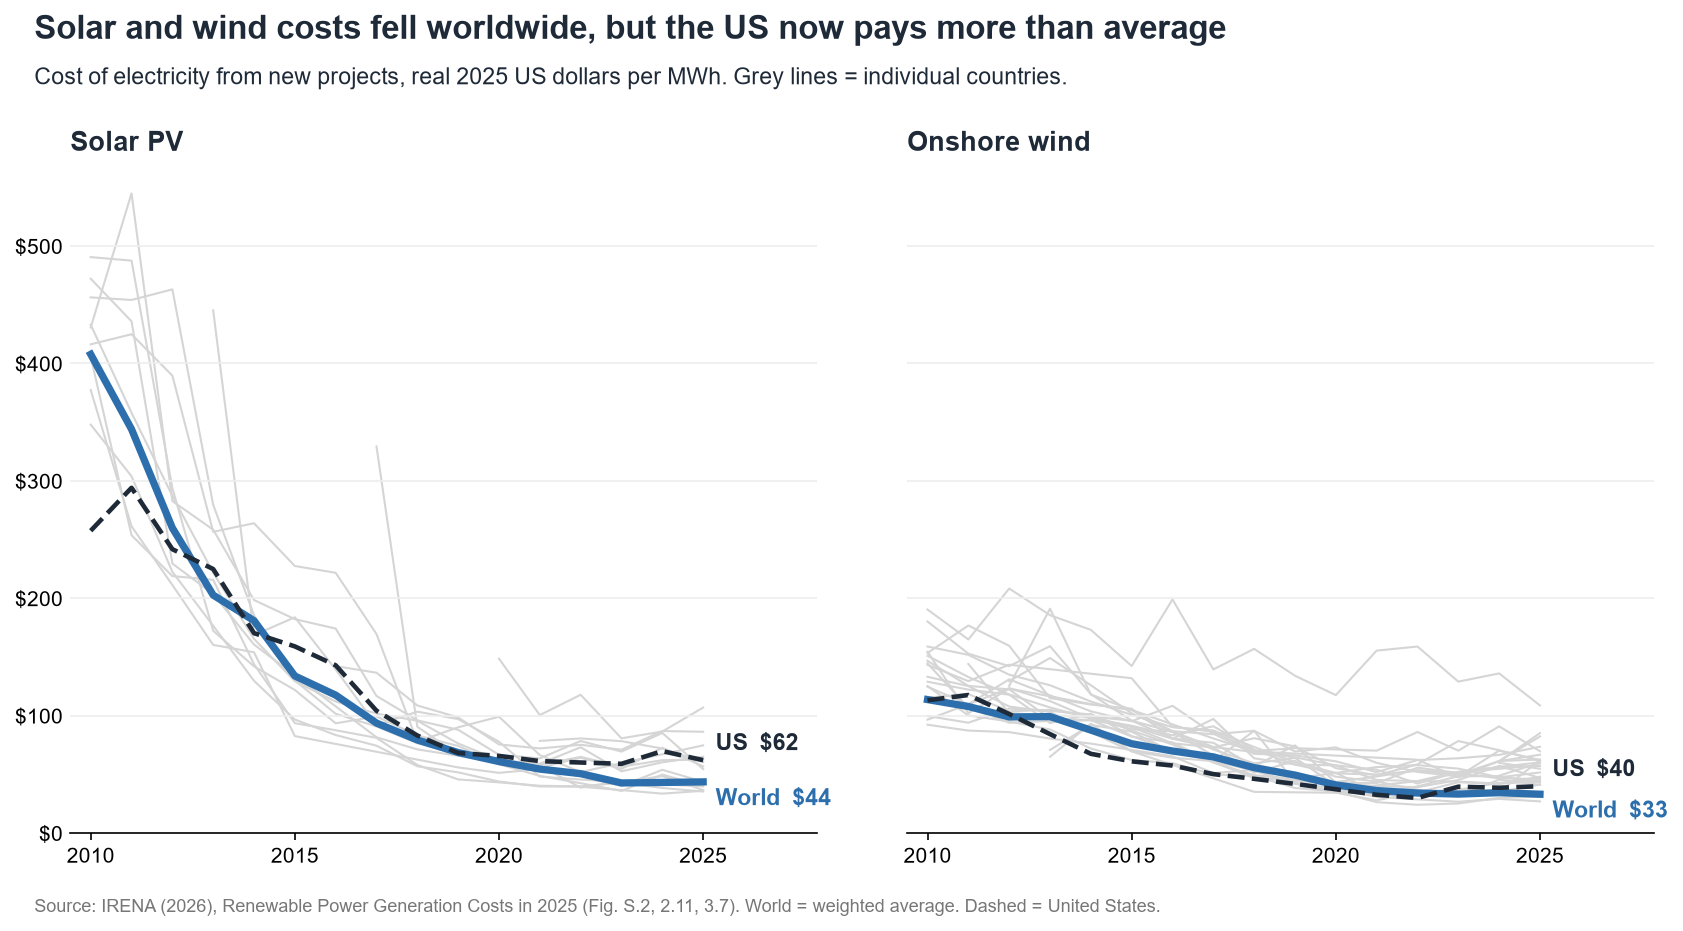

In [32]:
fig, axes = plt.subplots(1, 2, figsize=(12, 6.2), dpi=150, sharey=True)
for ax, (tech, pv) in zip(axes, [("Solar PV", irena_solar), ("Onshore wind", irena_wind)]):
    for c in pv.columns:
        if c not in ("Global average", "United States"):
            s = pv[c].dropna(); ax.plot(s.index, s.values, color="#D5D5D5", linewidth=1, zorder=1)
    us, gl = pv["United States"].dropna(), pv["Global average"].dropna()
    ax.plot(gl.index, gl.values, color=BLUE, linewidth=3.5, zorder=3)
    ax.plot(us.index, us.values, color=NAVY, linewidth=2.2, linestyle="--", zorder=4)
    ax.annotate(f"World  ${gl.iloc[-1]:.0f}", xy=(2025, gl.iloc[-1]), xytext=(6, -8), textcoords="offset points",
                color=BLUE, fontsize=11, fontweight="bold", va="center")
    ax.annotate(f"US  ${us.iloc[-1]:.0f}", xy=(2025, us.iloc[-1]), xytext=(6, 8), textcoords="offset points",
                color=NAVY, fontsize=11, fontweight="bold", va="center")
    ax.set_title(tech, loc="left", fontsize=13, fontweight="bold", color=NAVY)
    ax.set_xticks(range(2010, 2026, 5)); ax.set_xlim(2009.5, 2027.8); ax.set_ylim(bottom=0)
    ax.grid(axis="y", color="#EEEEEE")
    for side in ("top", "right", "left"):
        ax.spines[side].set_visible(False)
    ax.tick_params(axis="y", length=0)
axes[0].yaxis.set_major_formatter(lambda v, _: f"${v:.0f}")
fig.suptitle("Solar and wind costs fell worldwide, but the US now pays more than average",
             x=0.05, ha="left", fontsize=16, fontweight="bold", color=NAVY)
fig.text(0.05, 0.905, "Cost of electricity from new projects, real 2025 US dollars per MWh. Grey lines = individual countries.",
         fontsize=11, color=NAVY)
fig.text(0.05, 0.015, "Source: IRENA (2026), Renewable Power Generation Costs in 2025 (Fig. S.2, 2.11, 3.7). "
         "World = weighted average. Dashed = United States.", fontsize=8.5, color="#777777")
fig.subplots_adjust(left=0.07, right=0.95, top=0.82, bottom=0.10, wspace=0.12)
fig.savefig("q1_chart2_irena_cost_by_country.png", dpi=300, bbox_inches="tight")
plt.show()

**Interpretation (Q1b):** In 2025, new utility-scale solar cost $62 per MWh in the US versus a $44 global average, and new onshore wind cost $40 versus $33 (real 2025 dollars). Since 2010, the global average fell by about 89% for solar and 71% for wind, and almost every country (grey lines) followed the same path, so the decline is global. Even so, the US now pays roughly 40% more for solar and 20% more for wind than the world average. *(The deck shows the 2025 comparison as an Excel bar chart; this chart shows the full trend behind it.)*

---
# Q2 (Tyler): How fast has the electricity mix changed in the US and worldwide?
**Source:** Our World in Data, *Share of electricity by source* (`share-elec-by-source.csv`).

In [33]:
q2 = pd.read_excel(DATA_FILE, sheet_name="Q2 Raw Data")
q2.head()

,Entity,Code,Year,Coal,Gas,Hydropower,Solar,Wind,Oil,Nuclear,Other renewables,Bioenergy,Other
0,ASEAN (Ember),NaN,2000,20.073397,43.367830,13.314500,0.0,0.0,17.224627,0.0,4.469849,1.549794,23.244270
1,ASEAN (Ember),NaN,2001,21.294035,47.004370,13.411835,0.0,0.0,12.646572,0.0,4.048483,1.594707,18.289762
2,ASEAN (Ember),NaN,2002,21.567904,48.228260,12.304070,0.0,0.0,12.537224,0.0,3.834345,1.528198,17.899767
3,ASEAN (Ember),NaN,2003,22.258347,49.423958,11.610299,0.0,0.0,11.649574,0.0,3.434432,1.623391,16.707396
4,ASEAN (Ember),NaN,2004,23.159020,49.165344,10.670345,0.0,0.0,11.979219,0.0,3.336622,1.689455,17.005296


In [34]:
energy = q2[q2["Entity"].isin(["United States", "World"])].copy()
energy["Wind + Solar"] = energy["Wind"] + energy["Solar"]
years = [2000, 2005, 2010, 2015, 2020, 2025]
comparison = energy[energy["Year"].isin(years)]
comparison[["Entity", "Year", "Wind", "Solar", "Wind + Solar"]]

,Entity,Year,Wind,Solar,Wind + Solar
7372,United States,2000,0.147024,0.012888,0.159912
7377,United States,2005,0.441389,0.013631,0.455020
7382,United States,2010,2.300714,0.029412,2.330126
7387,United States,2015,4.669943,0.955683,5.625626
7392,United States,2020,8.358273,3.233099,11.591372
7397,United States,2025,10.274592,8.602612,18.877204
7744,World,2000,0.203878,0.006676,0.210553
7749,World,2005,0.575712,0.021782,0.597494
7754,World,2010,1.627135,0.151478,1.778614
7759,World,2015,3.456453,1.066604,4.523057


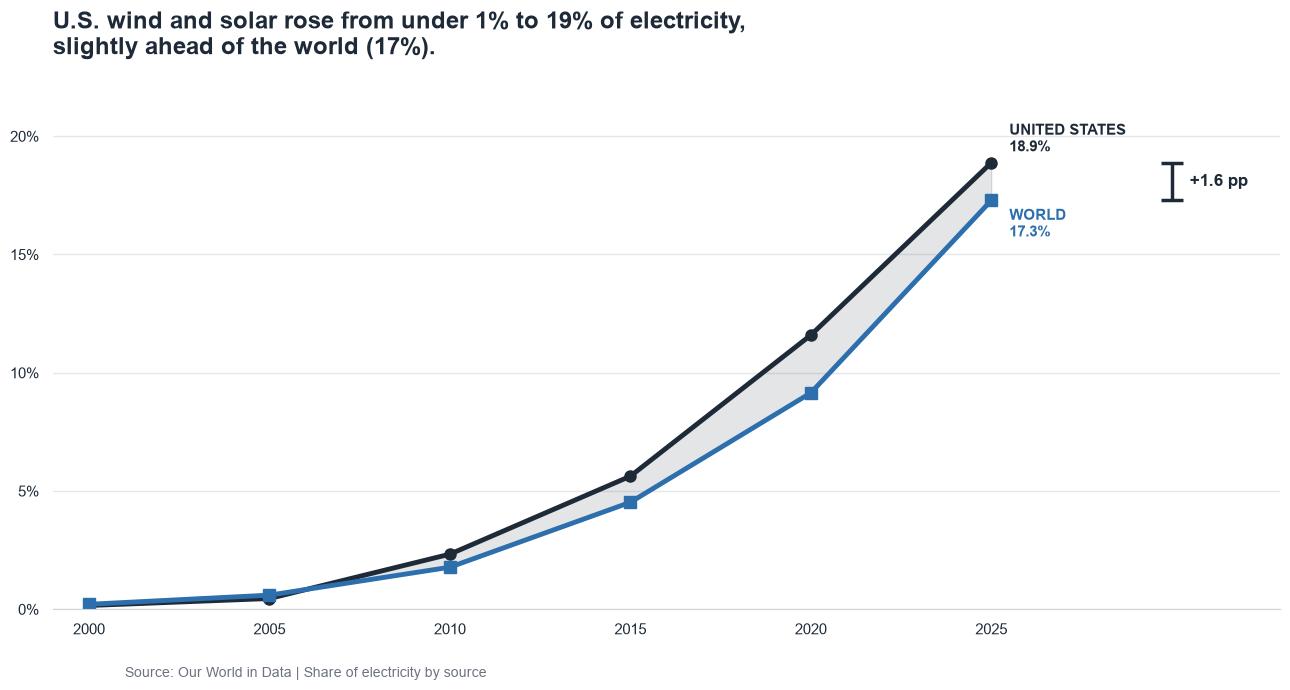

In [35]:
us = comparison[comparison["Entity"] == "United States"].sort_values("Year")
world = comparison[comparison["Entity"] == "World"].sort_values("Year")

fig, ax = plt.subplots(figsize=(13, 7))
fig.patch.set_facecolor("white"); ax.set_facecolor("white")

ax.plot(us["Year"], us["Wind + Solar"], color=NAVY, linewidth=3.5, marker="o", markersize=8, label="United States")
ax.plot(world["Year"], world["Wind + Solar"], color=BLUE, linewidth=3.5, marker="s", markersize=8, label="World")
ax.fill_between(us["Year"], us["Wind + Solar"], world["Wind + Solar"], color=NAVY, alpha=0.12)

ax.set_title("U.S. wind and solar rose from under 1% to 19% of electricity,\nslightly ahead of the world (17%).",
             fontsize=17, fontweight="bold", loc="left", pad=25, color=NAVY)
ax.set_xlim(1999, 2033); ax.set_ylim(0, 22)
ax.set_xticks(years)
ax.set_yticks([0, 5, 10, 15, 20]); ax.set_yticklabels(["0%", "5%", "10%", "15%", "20%"])
ax.tick_params(axis="both", length=0, labelsize=11, pad=10, colors=NAVY)
ax.grid(axis="y", color="#E5E7EB", linewidth=1); ax.set_axisbelow(True)
for side in ("top", "right", "left"):
    ax.spines[side].set_visible(False)
ax.spines["bottom"].set_color("#D1D5DB")

us_2025 = us.loc[us["Year"] == 2025, "Wind + Solar"].iloc[0]
world_2025 = world.loc[world["Year"] == 2025, "Wind + Solar"].iloc[0]
gap = us_2025 - world_2025

ax.text(2025.5, us_2025 + 0.3, f"UNITED STATES\n{us_2025:.1f}%", color=NAVY, fontsize=11, fontweight="bold", va="bottom")
ax.text(2025.5, world_2025 - 0.3, f"WORLD\n{world_2025:.1f}%", color=BLUE, fontsize=11, fontweight="bold", va="top")

bracket_x = 2030
ax.vlines(x=bracket_x, ymin=world_2025, ymax=us_2025, color=NAVY, linewidth=2.5)
ax.hlines(y=[world_2025, us_2025], xmin=bracket_x - 0.3, xmax=bracket_x + 0.3, color=NAVY, linewidth=2.5)
ax.text(bracket_x + 0.5, (us_2025 + world_2025) / 2, f"+{gap:.1f} pp", fontsize=12, fontweight="bold", color=NAVY, va="center")

fig.text(0.10, 0.025, "Source: Our World in Data | Share of electricity by source", fontsize=10, color="#6B7280")
plt.tight_layout(rect=[0, 0.06, 1, 1])
plt.savefig("q2_chart1_us_vs_world_wind_solar.png", dpi=300, bbox_inches="tight", facecolor="white")
plt.show()

In [36]:
# Where does the US rank among countries in 2025? (countries only: OWID region aggregates have no ISO code)
countries = q2[(q2["Year"] == 2025) & q2["Code"].notna() & ~q2["Code"].astype(str).str.startswith("OWID")].copy()
countries["Wind + Solar"] = countries["Wind"] + countries["Solar"]
countries = countries.dropna(subset=["Wind + Solar"])

us_share = countries.loc[countries["Entity"] == "United States", "Wind + Solar"].iloc[0]
median = countries["Wind + Solar"].median()
below_us = (countries["Wind + Solar"] < us_share).sum()
total = len(countries)

print(f"Countries analyzed: {total}")
print(f"Median country: {median:.2f}%")
print(f"United States: {us_share:.2f}%")
print(f"Countries below the U.S.: {below_us}")
print(f"Percentage below the U.S.: {below_us / total * 100:.1f}%")

Countries analyzed: 88
Median country: 13.09%
United States: 18.88%
Countries below the U.S.: 53
Percentage below the U.S.: 60.2%


**Interpretation (Q2):** *Draft from the chart numbers — Tyler to confirm or replace.* Between 2000 and 2025, wind and solar grew from 0.2% to 18.9% of US electricity and from 0.2% to 17.3% worldwide, putting the US 1.6 percentage points ahead of the world. In 2025 the US share is higher than in about 60% of the 88 countries with data (median country: 13.1%), so the US is switching, but only slightly faster than average.

---
# Q3 (Taniya): Which countries are switching fastest?
**Source:** Our World in Data (Ember; Energy Institute), share of electricity by source, 2015 and 2024.
Countries generating 20+ TWh in 2024. Venezuela's drop reflects an economic crisis, not a policy switch.

                      Fossil fuels  Solar + wind  Hydro  Nuclear  Other
Country                                                                
Portugal                    -37.56         21.10  14.57     0.00   1.90
Netherlands                 -37.36         37.26  -0.01    -0.82   0.93
Belarus                     -36.32          0.89   0.55    34.24   0.64
Venezuela                   -32.33         -0.05  32.36     0.00   0.00
United Arab Emirates        -31.49          8.45   0.00    22.92   0.12
Chile                       -26.84         30.07  -1.90     0.00  -1.34
Denmark                     -23.42         17.81  -0.01     0.00   5.62
Jordan                      -22.87         23.10  -0.18     0.00  -0.05
Bulgaria                    -21.58         12.33  -4.32     9.63   3.94
Ecuador                     -21.34          0.28  20.21     0.00   0.84
United States                -8.72         11.58  -0.57    -1.71  -0.57
World                        -7.39         10.51  -1.84    -1.57

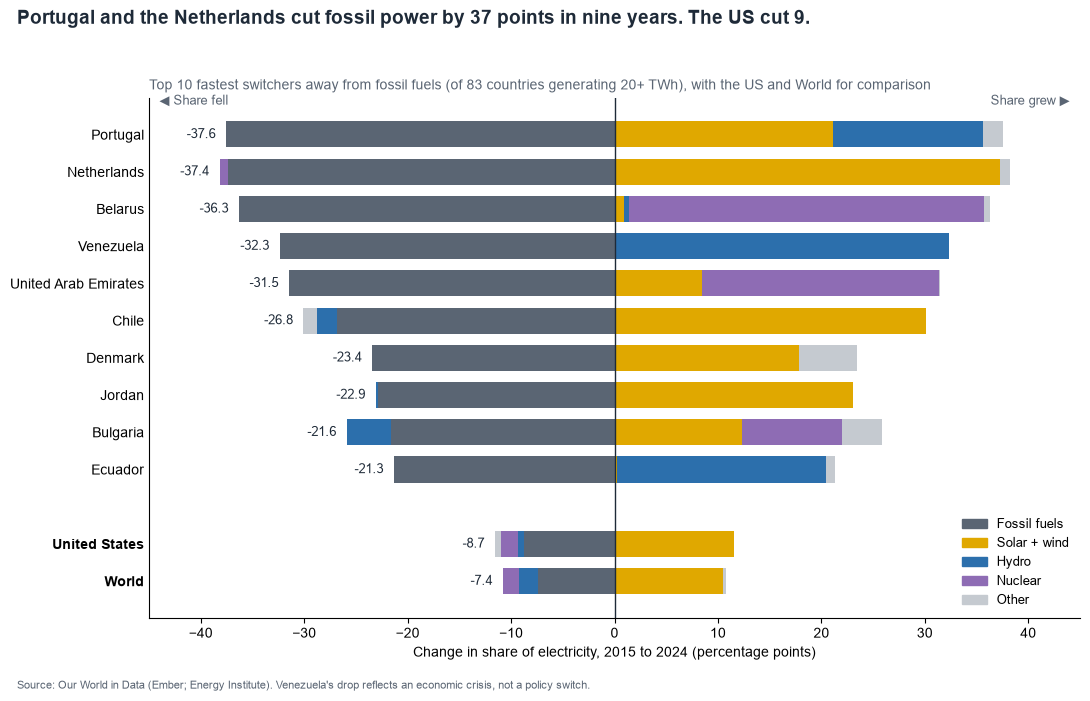

In [37]:
# ---- 0. Load Taniya's cleaned 2015/2024 data from the team workbook ----
df = pd.read_excel(DATA_FILE, sheet_name="Q3 Raw Data")
df["Solar_Wind"] = df["Solar_pct"] + df["Wind_pct"]
df["Other"] = df["Bioenergy_pct"] + df["Other_Renewables_pct"]

cols = {"Fossil_Fuels_Total_pct": "Fossil fuels", "Solar_Wind": "Solar + wind",
        "Hydro_pct": "Hydro", "Nuclear_pct": "Nuclear", "Other": "Other"}
wide = df.pivot(index="Country", columns="Year", values=list(cols))
change = pd.DataFrame({name: wide[(c, 2024)] - wide[(c, 2015)] for c, name in cols.items()})

# ---- 2. Keep large countries (>= 20 TWh in 2024), pick top 10 + US + World ----
big = df[(df.Year == 2024) & (df.Electricity_Generation_TWh >= 20) & (df.Country != "World")].Country
top10 = change.loc[big].sort_values("Fossil fuels").head(10)
print(pd.concat([top10, change.loc[["United States", "World"]]]).round(2))

# ---- 3. Diverging stacked bar: shares that fell (left) vs grew (right) ----
palette = {"Fossil fuels": "#5A6573", "Solar + wind": "#E0A800",
           "Hydro": "#2C6FAC", "Nuclear": "#8E6CB4", "Other": "#C5CAD0"}   # Other: green -> light gray
labels = list(top10.index) + ["", "United States", "World"]
data = pd.concat([top10, pd.DataFrame([[0] * 5], columns=top10.columns, index=[""]),
                  change.loc[["United States", "World"]]])
y = range(len(data))[::-1]

fig, ax = plt.subplots(figsize=(11, 7))
for i, (country, row) in zip(y, data.iterrows()):
    left_pos, left_neg = 0, 0
    for src in cols.values():
        v = row[src]
        if v >= 0:
            ax.barh(i, v, left=left_pos, color=palette[src], height=0.7); left_pos += v
        else:
            ax.barh(i, v, left=left_neg, color=palette[src], height=0.7); left_neg += v
    if country:
        ax.text(left_neg - 1, i, f"{row['Fossil fuels']:.1f}", va="center", ha="right", fontsize=9, color="#1E2A38")

ax.set_yticks(list(y)); ax.set_yticklabels(labels, fontsize=10); ax.tick_params(axis="y", length=0)
for t in ax.get_yticklabels():
    if t.get_text() in ("United States", "World"):
        t.set_fontweight("bold")
ax.axvline(0, color="#1E2A38", linewidth=1)
ax.set_xlim(-45, 45)
ax.set_xlabel("Change in share of electricity, 2015 to 2024 (percentage points)")
ax.spines[["top", "right"]].set_visible(False)
handles = [plt.Rectangle((0, 0), 1, 1, color=c) for c in palette.values()]
ax.legend(handles, palette.keys(), loc="lower right", frameon=False, fontsize=9)
ax.text(-44, len(data) - 0.2, "◀ Share fell", fontsize=9, color="#5A6573")
ax.text(44, len(data) - 0.2, "Share grew ▶", fontsize=9, color="#5A6573", ha="right")
fig.suptitle("Portugal and the Netherlands cut fossil power by 37 points in nine years. The US cut 9.",
             x=0.02, ha="left", fontsize=14, fontweight="bold", color="#1E2A38")
ax.set_title("Top 10 fastest switchers away from fossil fuels (of 83 countries generating 20+ TWh), "
             "with the US and World for comparison", loc="left", fontsize=10, color="#5A6573")
fig.text(0.02, 0.01, "Source: Our World in Data (Ember; Energy Institute). Venezuela's drop reflects an "
         "economic crisis, not a policy switch.", fontsize=8, color="#5A6573")
plt.tight_layout(rect=[0, 0.03, 1, 0.95])
plt.savefig("q3_chart1_top10_switchers.png", dpi=200)
plt.show()

**Interpretation (Q3):** _Draft from the chart numbers — Taniya to confirm or replace._ Between 2015 and 2024, the fastest switchers cut fossil fuels' share of electricity by 21–38 percentage points (Portugal −37.6, the Netherlands −37.4), mostly by adding solar and wind, though Belarus and the UAE switched mainly through nuclear and Venezuela's drop reflects an economic crisis. The US cut fossil power by only 8.7 points, close to the world average of 7.4, despite solar and wind growing by 11.6 points.

---
## Data sources (all raw data is in `IE6600 - Hackathon Team 4.xlsx`)
| Question | Dataset | Workbook tab | Link |
|---|---|---|---|
| Q1a | Lazard LCOE+ v18.0 (June 2025), p.14 | `Q1 Raw data` (Lazard rows) | https://www.lazard.com/media/5tlbhyla/lazards-lcoeplus-june-2025-_vf.pdf#page=14 |
| Q1b | IRENA (2026), Renewable Power Generation Costs in 2025 | `Q1 Raw data` (IRENA rows) | https://www.irena.org/Publications/2026/Jul/Renewable-Power-Generation-Costs-in-2025 |
| Q2 | Our World in Data, share of electricity by source | `Q2 Raw Data` | https://ourworldindata.org/electricity-mix |
| Q3 | Our World in Data (Ember; Energy Institute), 2015 & 2024 | `Q3 Raw Data` | https://ourworldindata.org/electricity-mix |